# Student Performance — At-Risk Prediction
IT3091 Machine Learning | Guided Data Track | Education (Code 3)

**Member 2 individual project:** IT24104122 — M.M.N. Mapa
**Dataset:** UCI Student Performance (Math), `student-mat.csv`
**Random seed:** 42 (fixed throughout for reproducibility)

**Scope:** missing-value audit, data quality documentation, parental education and study time EDA, shared missing-value handling, Random Forest with feature importance, data dictionary.

In [1]:
import pandas as pd
import numpy as np
import hashlib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

## Step 1 — Data Audit
**Load + Dataset** Fingerprint

In [2]:
DATA_PATH = "../data/student-mat.csv"

df_raw = pd.read_csv(DATA_PATH, sep=";")

with open(DATA_PATH, "rb") as f:
    fingerprint = hashlib.md5(f.read()).hexdigest()

print(f"Shape: {df_raw.shape}")
print(f"MD5 fingerprint: {fingerprint}")
df_raw.head()

Shape: (395, 33)
MD5 fingerprint: 4dc304be95c60de6ee13fb8769469dd7


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


**Data Dictionary** (33 columns, with the role each column plays in this project)

In [3]:
DICT_PATH = "../data/data_dictionary.csv"

data_dictionary = pd.read_csv(DICT_PATH)
data_dictionary[["column", "type", "source_description", "model_role", "decision_note"]]

,column,type,source_description,model_role,decision_note
0,school,categorical,"student's school (binary: ""GP"" - Gabriel Perei...",predictor,one-hot encoded
1,sex,categorical,"student's sex (binary: ""F"" - female or ""M"" - m...",predictor,one-hot encoded (binary)
2,age,numeric / ordered,student's age (numeric: from 15 to 22),predictor,standard scaled
3,address,categorical,"student's home address type (binary: ""U"" - urb...",predictor,one-hot encoded (binary)
4,famsize,categorical,"family size (binary: ""LE3"" - less or equal to ...",predictor,one-hot encoded (binary)
5,Pstatus,categorical,"parent's cohabitation status (binary: ""T"" - li...",predictor,one-hot encoded (binary)
6,Medu,numeric / ordered,"mother's education (numeric: 0 - none, 1 - pri...",predictor,standard scaled; also used to derive parent_ed...
7,Fedu,numeric / ordered,"father's education (numeric: 0 - none, 1 - pri...",predictor,standard scaled; also used to derive parent_ed...
8,Mjob,categorical,"mother's job (nominal: ""teacher"", ""health"" car...",predictor,one-hot encoded (nominal)
9,Fjob,categorical,"father's job (nominal: ""teacher"", ""health"" car...",predictor,one-hot encoded (nominal)


**Structural Inspection**

In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

**Missing-Value Audit** (nulls, blank cells and sentinel strings)

In [5]:
null_counts = df_raw.isnull().sum()
cols_with_nulls = null_counts[null_counts > 0]

print("Null values per column:")
if len(cols_with_nulls) == 0:
    print("None found")
else:
    print(cols_with_nulls)

# A file can hide missing values behind placeholders, so check for those as well
sentinels = ["", "?", "na", "n/a", "null", "none", "nan"]
sentinel_mask = df_raw.astype(str).apply(lambda s: s.str.strip().str.lower().isin(sentinels))
sentinel_counts = sentinel_mask.sum()

print(f"\nSentinel / blank cells: {int(sentinel_counts.sum())}")
print(sentinel_counts[sentinel_counts > 0] if sentinel_counts.sum() > 0 else "None found")

Null values per column:
None found

Sentinel / blank cells: 0
None found


**Missing-value audit table** (per column, saved for the quality documentation)

In [6]:
audit_table = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_count": df_raw.isnull().sum(),
    "missing_percent": df_raw.isnull().mean() * 100,
    "sentinel_count": sentinel_counts,
    "unique_values": df_raw.nunique(),
})
audit_table.to_csv("missing_value_audit.csv")
audit_table

,dtype,missing_count,missing_percent,sentinel_count,unique_values
school,str,0,0.0,0,2
sex,str,0,0.0,0,2
age,int64,0,0.0,0,8
address,str,0,0.0,0,2
famsize,str,0,0.0,0,2
Pstatus,str,0,0.0,0,2
Medu,int64,0,0.0,0,5
Fedu,int64,0,0.0,0,5
Mjob,str,0,0.0,0,5
Fjob,str,0,0.0,0,5


**Duplicate** check

In [7]:
duplicate_count = df_raw.duplicated().sum()
print(f"Fully duplicate rows: {duplicate_count}")

# The UCI file has no real student ID, so shared demographics are NOT treated as duplicates
proxy_key = ["school", "sex", "age", "address", "famsize", "Pstatus", "Medu", "Fedu",
             "Mjob", "Fjob", "reason", "nursery", "internet"]
repeated_proxy = df_raw.duplicated(subset=proxy_key).sum()
print(f"Rows sharing the 13-field demographic key with another row: {repeated_proxy}")
print("(Reported only — two different students can share these fields, so none are dropped.)")

Fully duplicate rows: 0
Rows sharing the 13-field demographic key with another row: 4
(Reported only — two different students can share these fields, so none are dropped.)


**Inconsistent category** formatting check

In [8]:
categorical_cols = df_raw.select_dtypes(exclude=np.number).columns

for col in categorical_cols:
    unique_values = df_raw[col].unique()
    unique_values_sorted = sorted(unique_values)
    print(f"\n{col}: {unique_values_sorted}")


school: ['GP', 'MS']

sex: ['F', 'M']

address: ['R', 'U']

famsize: ['GT3', 'LE3']

Pstatus: ['A', 'T']

Mjob: ['at_home', 'health', 'other', 'services', 'teacher']

Fjob: ['at_home', 'health', 'other', 'services', 'teacher']

reason: ['course', 'home', 'other', 'reputation']

guardian: ['father', 'mother', 'other']

schoolsup: ['no', 'yes']

famsup: ['no', 'yes']

paid: ['no', 'yes']

activities: ['no', 'yes']

nursery: ['no', 'yes']

higher: ['no', 'yes']

internet: ['no', 'yes']

romantic: ['no', 'yes']


**Numeric Range** sanity check

In [9]:
numeric_cols = df_raw.select_dtypes(include=np.number).columns
summary = df_raw[numeric_cols].describe().T
summary

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


**Data quality findings**
- No null cells, no blank/sentinel placeholders and no fully duplicate rows were found, so nothing needs to be dropped or filled in this file.
- Categorical columns are consistent (no case or whitespace variants).
- Numeric ranges match the dictionary: ordinal scales stay inside their documented bounds, and `absences` has a long right tail (max 75) that is kept as a plausible extreme.
- `failures` only contains the codes 0–3 even though the source wording says "n if 1<=n<3, else 4". The observed codes are preserved, not recoded.
- `G3 = 0` is a valid observed grade. There is no dropout label, so zeros are retained and investigated, not removed.

## Step 2 — Deterministic Cleaning
Safe to apply to the full dataset: no statistics are learned here, only normalization.

In [10]:
df = df_raw.copy()

for col in categorical_cols:
    df[col] = df[col].str.strip()

rows_before = len(df)
df = df.drop_duplicates()
rows_after = len(df)

print(f"Dropped {rows_before - rows_after} duplicate rows")
print(f"Shape after cleaning: {df.shape}")

Dropped 0 duplicate rows
Shape after cleaning: (395, 33)


## Step 3 — Train/Test Split
Split immediately after deterministic cleaning, before EDA and before any fitted
preprocessing (imputers/encoders/scalers). This is the leakage boundary: everything from
here on that *learns* a statistic is fit on the training set only.

In [11]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["G3"])
y = df["G3"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Train shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")

train_mean = y_train.mean()
train_std = y_train.std()
test_mean = y_test.mean()
test_std = y_test.std()

print(f"Train target mean/std: {train_mean:.2f} / {train_std:.2f}")
print(f"Test target mean/std:  {test_mean:.2f} / {test_std:.2f}")

Train shape: (316, 32)
Test shape: (79, 32)
Train target mean/std: 10.33 / 4.59
Test target mean/std:  10.77 / 4.56


## Step 4 — Exploratory Data Analysis (Training Set Only)
All plots/stats below use `X_train`/`y_train` — the test set stays untouched
until final evaluation. Focus: parental education and study time.

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

train_df = X_train.copy()
train_df["G3"] = y_train

**G3 Distribution + Skewness**

G3 skewness: -0.773


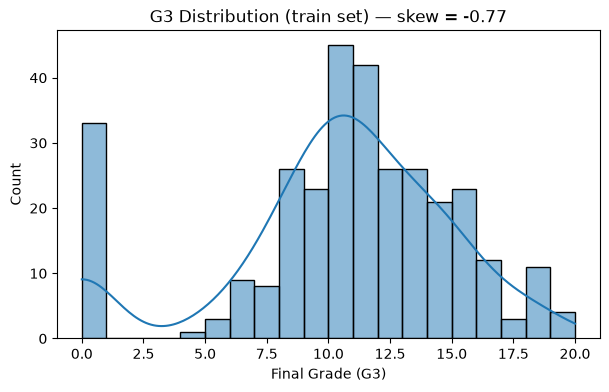

In [13]:
from scipy.stats import skew

g3_skew = skew(train_df["G3"])
print(f"G3 skewness: {g3_skew:.3f}")

plt.figure(figsize=(7, 4))
sns.histplot(train_df["G3"], bins=20, kde=True)
plt.title(f"G3 Distribution (train set) — skew = {g3_skew:.2f}")
plt.xlabel("Final Grade (G3)")
plt.show()

**G3 = 0 Investigation**

In [14]:
zero_g3 = train_df[train_df["G3"] == 0]
print(f"Students with G3 = 0: {len(zero_g3)} ({len(zero_g3) / len(train_df):.1%})")

zero_g3[["G1", "G2", "absences", "failures", "studytime"]].describe()

Students with G3 = 0: 33 (10.4%)


,G1,G2,absences,failures,studytime
count,33.000000,33.000000,33.0,33.000000,33.000000
mean,7.606061,4.363636,0.0,1.000000,1.878788
std,1.766695,3.655631,0.0,1.089725,0.819969
min,5.000000,0.000000,0.0,0.000000,1.000000
25%,6.000000,0.000000,0.0,0.000000,1.000000
50%,7.000000,5.000000,0.0,1.000000,2.000000
75%,9.000000,7.000000,0.0,2.000000,2.000000
max,12.000000,10.000000,0.0,3.000000,4.000000


**Parental Education vs G3**

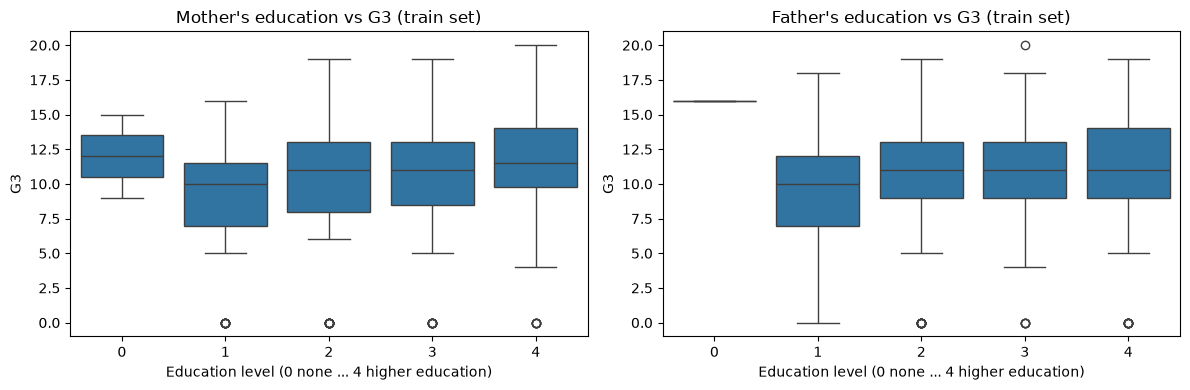


--- G3 by Medu ---
           mean  median       std  count
Medu                                    
0     12.000000    12.0  4.242641      2
1      8.425532    10.0  4.744538     47
2      9.785714    11.0  4.594579     84
3     10.421687    11.0  4.667272     83
4     11.560000    11.5  4.134897    100

--- G3 by Fedu ---
           mean  median       std  count
Fedu                                    
0     16.000000    16.0       NaN      1
1      8.921875    10.0  4.761968     64
2     10.200000    11.0  4.748033     90
3     11.023810    11.0  3.951441     84
4     10.805195    11.0  4.712913     77


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col, label in zip(axes, ["Medu", "Fedu"], ["Mother's education", "Father's education"]):
    sns.boxplot(data=train_df, x=col, y="G3", ax=ax)
    ax.set_title(f"{label} vs G3 (train set)")
    ax.set_xlabel("Education level (0 none ... 4 higher education)")

plt.tight_layout()
plt.show()

for col in ["Medu", "Fedu"]:
    print(f"\n--- G3 by {col} ---")
    print(train_df.groupby(col)["G3"].agg(["mean", "median", "std", "count"]))

**Study Time vs G3**

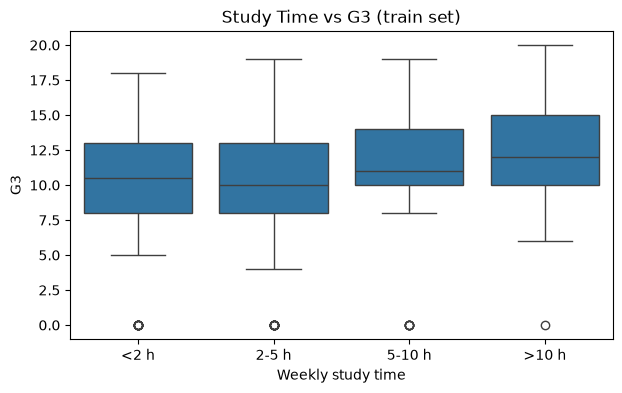

                mean  median       std  count
studytime                                    
1           9.829268    10.5  5.049887     82
2          10.031646    10.0  4.173652    158
3          11.200000    11.0  4.805090     55
4          12.190476    12.0  4.697010     21


In [16]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=train_df, x="studytime", y="G3")
plt.xticks(range(4), ["<2 h", "2-5 h", "5-10 h", ">10 h"])
plt.title("Study Time vs G3 (train set)")
plt.xlabel("Weekly study time")
plt.show()

print(train_df.groupby("studytime")["G3"].agg(["mean", "median", "std", "count"]))

**Rank correlation** of parental education and study time with G3 (Spearman, since these are ordinal)

In [17]:
from scipy.stats import spearmanr

rows = []
for col in ["Medu", "Fedu", "studytime"]:
    rho, p = spearmanr(train_df[col], train_df["G3"])
    rows.append({"feature": col, "spearman_rho": rho, "p_value": p})

pd.DataFrame(rows).round(4)

,feature,spearman_rho,p_value
0,Medu,0.2134,0.0001
1,Fedu,0.1501,0.0075
2,studytime,0.1255,0.0257


**Reading the EDA:** these plots show distribution, group size and overlap. They describe association only and do not prove that parental education or study time *cause* grade differences. Groups at the extremes (e.g. `Medu = 0`, `studytime = 4`) are small, so their means are unstable.

**Correlation Heatmap** (G1/G2 vs G3 leakage check)

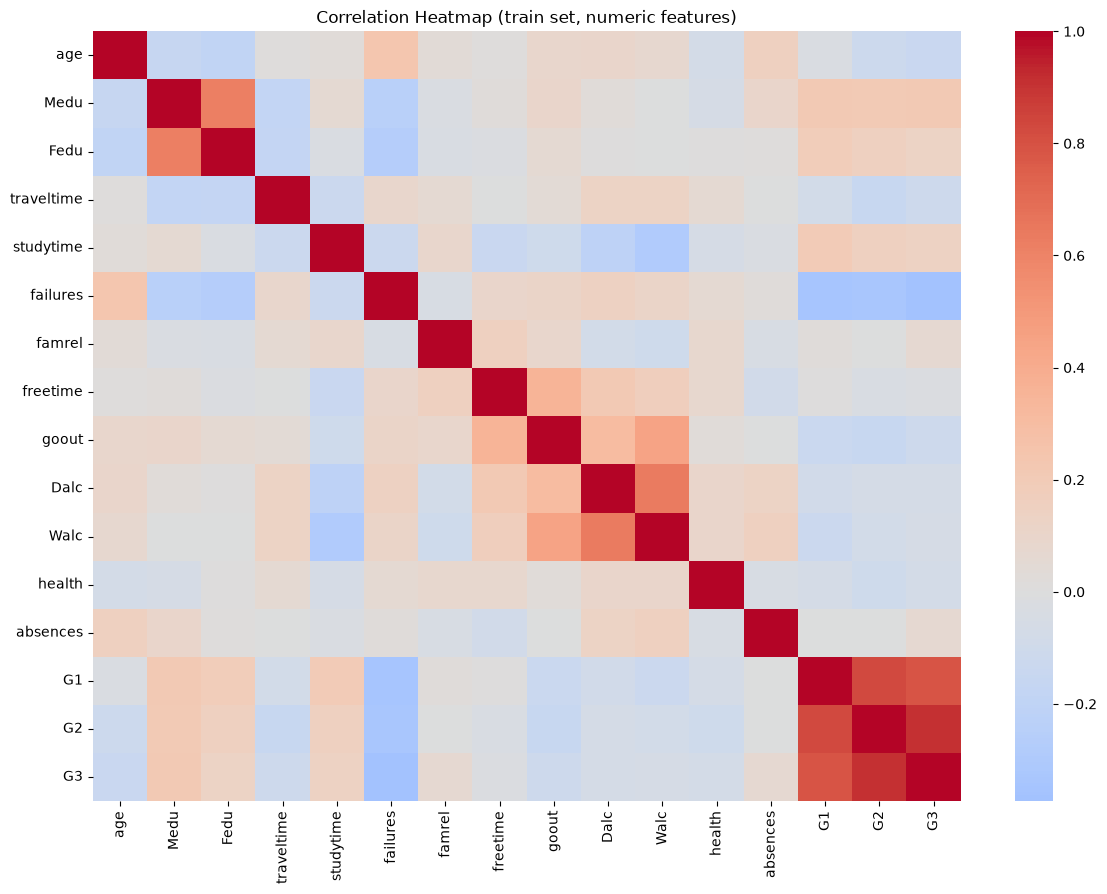

G3            1.000000
G2            0.907924
G1            0.791559
Medu          0.215968
studytime     0.138200
Fedu          0.135265
famrel        0.069409
absences      0.064607
freetime     -0.015244
Walc         -0.057363
Dalc         -0.064698
health       -0.068857
goout        -0.106024
traveltime   -0.106752
age          -0.146241
failures     -0.373769
Name: G3, dtype: float64


In [18]:
numeric_train = train_df.select_dtypes(include=np.number)
corr = numeric_train.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap (train set, numeric features)")
plt.show()

print(corr["G3"].sort_values(ascending=False))

## Step 5 — Preprocessing Pipeline (shared missing-value handling)
Built with sklearn `ColumnTransformer` + `Pipeline` so it can be fit on the
training set only and reused identically for every model.
Missing values are handled **inside** the pipeline: median imputation for numeric
columns and most-frequent imputation for categorical columns, learned from the
training data only. This file has no missing cells, so the imputers are a safeguard
that changes nothing here, but they keep the pipeline safe for new data.
Two deterministic features are derived without G3: `parent_education_max` and `has_past_failure`.
`absences` gets a log1p transform.

In [19]:
binary_cols = ["school", "sex", "address", "famsize", "Pstatus",
                "schoolsup", "famsup", "paid", "activities", "nursery",
                "higher", "internet", "romantic"]

nominal_cols = ["Mjob", "Fjob", "reason", "guardian"]

numeric_cols_to_scale = ["age", "Medu", "Fedu", "traveltime", "studytime",
                          "failures", "famrel", "freetime", "goout", "Dalc",
                          "Walc", "health", "absences", "G1", "G2",
                          "parent_education_max", "has_past_failure"]

**Feature engineering + log transform helper**

In [20]:
from sklearn.preprocessing import FunctionTransformer

def add_features(X):
    X = X.copy()
    X["parent_education_max"] = X[["Medu", "Fedu"]].max(axis=1)
    X["has_past_failure"] = (X["failures"] > 0).astype(int)
    X["absences"] = np.log1p(X["absences"])
    return X

feature_transformer = FunctionTransformer(add_features)

**ColumnTransformer** (imputer + encoder / scaler)

In [21]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("binary", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(drop="if_binary")),
        ]), binary_cols),
        ("nominal", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(handle_unknown="ignore")),
        ]), nominal_cols),
        ("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), numeric_cols_to_scale),
    ]
)

full_preprocessor = Pipeline(steps=[
    ("add_features", feature_transformer),
    ("column_transform", preprocessor),
])

**Fit -> Train, Transform -> Train + Test**

In [22]:
X_train_transformed = full_preprocessor.fit_transform(X_train)
X_test_transformed = full_preprocessor.transform(X_test)

print(f"Transformed train shape: {X_train_transformed.shape}")
print(f"Transformed test shape: {X_test_transformed.shape}")
print(f"Missing values left after preprocessing (train): {int(np.isnan(X_train_transformed).sum())}")

Transformed train shape: (316, 47)
Transformed test shape: (79, 47)
Missing values left after preprocessing (train): 0


## Step 6 — Baseline: Dummy Regressor
Predicts the training mean for every student. Any useful model must beat this.

In [23]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score

dummy_pipeline = Pipeline(steps=[
    ("preprocessor", full_preprocessor),
    ("model", DummyRegressor(strategy="mean")),
])

cv_scores = cross_val_score(
    dummy_pipeline, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error"
)
print(f"5-fold CV RMSE: {-cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")

dummy_pipeline.fit(X_train, y_train)

5-fold CV RMSE: 4.575 (+/- 0.372)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](32,)","['school','sex','age',...,'absences','G1','G2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,32
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('add_features', ...), ('column_transform', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. S

## Step 7 — Model: Random Forest

In [24]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline(steps=[
    ("preprocessor", full_preprocessor),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE)),
])

rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, None],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.7, 1.0],
}

rf_search = GridSearchCV(
    rf_pipeline, rf_param_grid, cv=5,
    scoring="neg_root_mean_squared_error", n_jobs=-1
)
rf_search.fit(X_train, y_train)

print(f"Best params: {rf_search.best_params_}")
print(f"Best CV RMSE: {-rf_search.best_score_:.3f}")

rf_best = rf_search.best_estimator_

Best params: {'model__max_depth': 10, 'model__max_features': 1.0, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Best CV RMSE: 1.391


## Step 8 — Evaluation
Test set is used here for the first and only time. RMSE, MAE, R² for the Random Forest
and the baseline, plus a train-vs-test gap to check for overfitting.

In [25]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

models = {
    "Dummy (mean)": dummy_pipeline,
    "Random Forest": rf_best,
}

**Computing metrics**

In [26]:
results = []

for name, model in models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_rmse = mean_squared_error(y_train, train_pred) ** 0.5
    test_rmse = mean_squared_error(y_test, test_pred) ** 0.5
    test_mae = mean_absolute_error(y_test, test_pred)
    test_r2 = r2_score(y_test, test_pred)

    results.append({
        "Model": name,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,
        "Train-Test Gap": test_rmse - train_rmse,
        "Test MAE": test_mae,
        "Test R2": test_r2,
    })

results_df = pd.DataFrame(results).sort_values("Test RMSE")
results_df

,Model,Train RMSE,Test RMSE,Train-Test Gap,Test MAE,Test R2
1,Random Forest,0.584068,1.983966,1.399899,1.206463,0.808041
0,Dummy (mean),4.583068,4.550181,-0.032888,3.645850,-0.009710


**Residual Analysis** (and actual vs predicted)

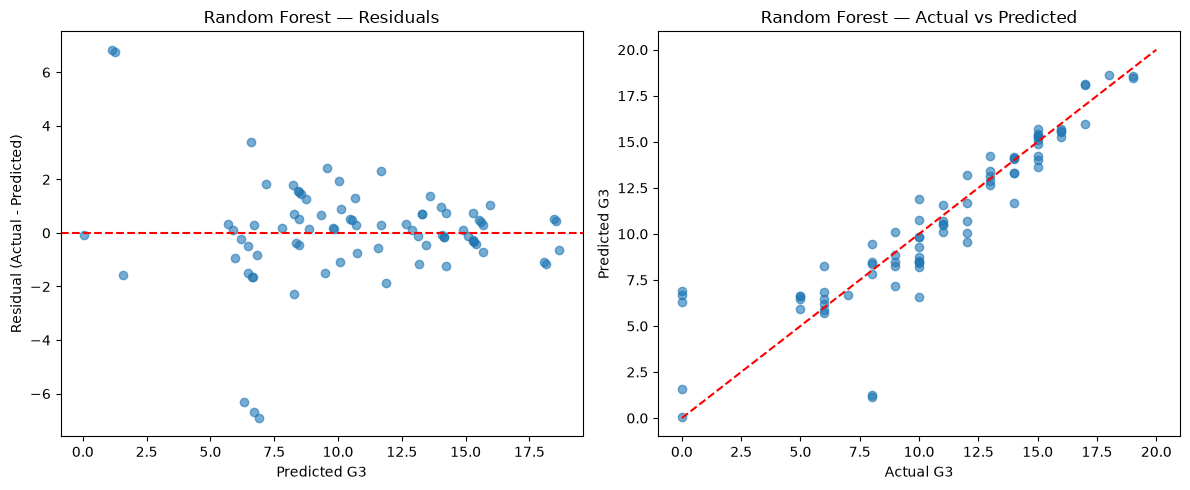

In [27]:
rf_test_pred = rf_best.predict(X_test)
residuals = y_test - rf_test_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(rf_test_pred, residuals, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Random Forest — Residuals")
axes[0].set_xlabel("Predicted G3")
axes[0].set_ylabel("Residual (Actual - Predicted)")

axes[1].scatter(y_test, rf_test_pred, alpha=0.6)
axes[1].plot([0, 20], [0, 20], color="red", linestyle="--")
axes[1].set_title("Random Forest — Actual vs Predicted")
axes[1].set_xlabel("Actual G3")
axes[1].set_ylabel("Predicted G3")

plt.tight_layout()
plt.show()

## Step 9 — Feature Importance
Impurity-based importance (native to Random Forest, measured from the training fit) compared against
permutation importance (model-agnostic, measured on the held-out test set) to check the two
methods agree on which features matter. Neither method identifies causes, and
correlated fields (e.g. `Medu`, `Fedu` and `parent_education_max`) can share importance.

In [28]:
rf_feature_names = rf_best.named_steps["preprocessor"].named_steps["column_transform"].get_feature_names_out()
rf_importances = rf_best.named_steps["model"].feature_importances_

tree_importance_df = pd.DataFrame({
    "feature": rf_feature_names,
    "importance": rf_importances,
}).sort_values("importance", ascending=False)

tree_importance_df.head(15)

,feature,importance
44,numeric__G2,0.792905
42,numeric__absences,0.109916
24,nominal__reason_home,0.019515
30,numeric__age,0.009989
43,numeric__G1,0.006126
36,numeric__famrel,0.004855
41,numeric__health,0.004109
38,numeric__goout,0.003968
23,nominal__reason_course,0.003653
34,numeric__studytime,0.003321


Permutation Importance

In [29]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_best, X_test, y_test, n_repeats=30,
    random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error"
)

perm_importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std,
}).sort_values("importance_mean", ascending=False)

perm_importance_df.head(15)

,feature,importance_mean,importance_std
31,G2,4.062873,0.345568
29,absences,0.513008,0.153168
13,studytime,0.079311,0.017228
2,age,0.057959,0.056674
23,famrel,0.044861,0.016595
30,G1,0.011800,0.014286
28,health,0.009292,0.011777
12,traveltime,0.007224,0.003139
27,Walc,0.005686,0.005978
21,internet,0.004725,0.002966


**Side by Side** Comparison Plot

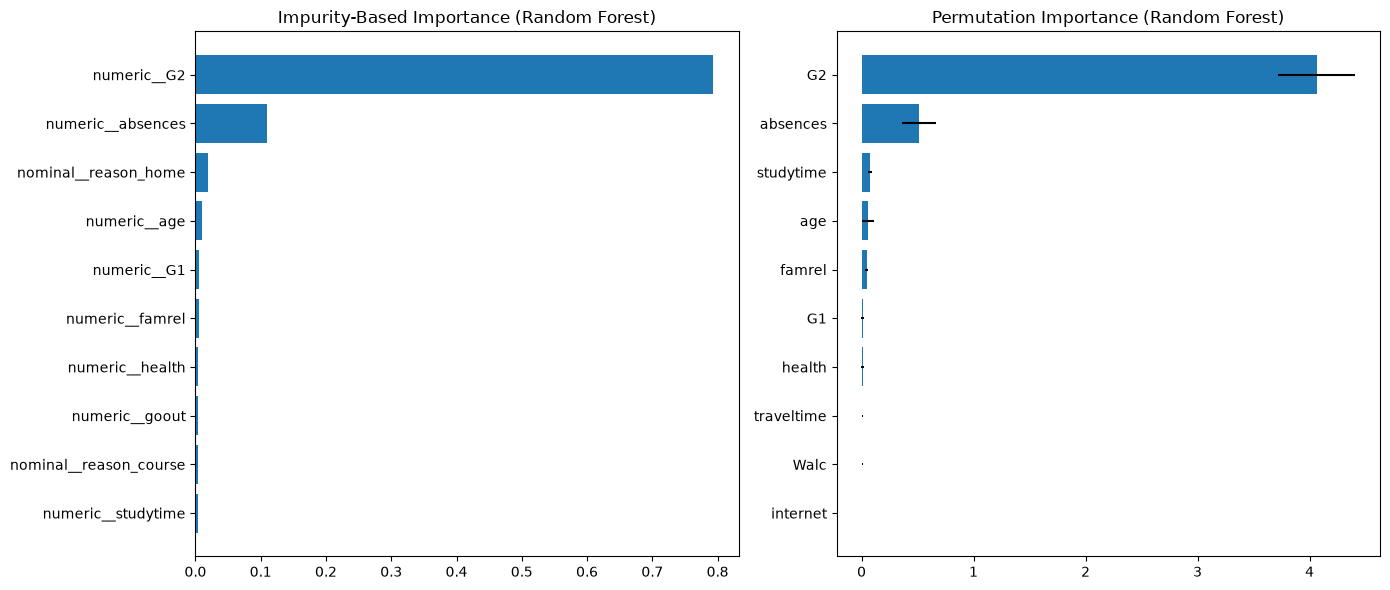

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

top_tree = tree_importance_df.head(10)
axes[0].barh(top_tree["feature"], top_tree["importance"])
axes[0].set_title("Impurity-Based Importance (Random Forest)")
axes[0].invert_yaxis()

top_perm = perm_importance_df.head(10)
axes[1].barh(top_perm["feature"], top_perm["importance_mean"], xerr=top_perm["importance_std"])
axes[1].set_title("Permutation Importance (Random Forest)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

**Where do parental education and study time rank?**

In [31]:
focus = ["Medu", "Fedu", "parent_education_max", "studytime"]

print("Permutation importance (test set):")
print(perm_importance_df[perm_importance_df["feature"].isin(focus)].round(4).to_string(index=False))

print("\nImpurity importance (train fit):")
tree_importance_df[tree_importance_df["feature"].str.contains("Medu|Fedu|parent_education_max|studytime")].round(4)

Permutation importance (test set):
  feature  importance_mean  importance_std
studytime           0.0793          0.0172
     Medu           0.0030          0.0029
     Fedu          -0.0051          0.0063

Impurity importance (train fit):


,feature,importance
34,numeric__studytime,0.0033
32,numeric__Fedu,0.0020
45,numeric__parent_education_max,0.0011
31,numeric__Medu,0.0008


## Step 10 — At-Risk Student Report
Using the Random Forest, flag students with predicted G3 < 10 on the test set, rank by
predicted grade, and attach each student's top global risk drivers.

In [32]:
test_predictions = rf_best.predict(X_test)

at_risk_df = X_test.copy()
at_risk_df["actual_G3"] = y_test.values
at_risk_df["predicted_G3"] = test_predictions
at_risk_df["at_risk"] = at_risk_df["predicted_G3"] < 10

at_risk_students = at_risk_df[at_risk_df["at_risk"]].sort_values("predicted_G3")

print(f"Flagged at-risk: {len(at_risk_students)} / {len(at_risk_df)} test students ({len(at_risk_students)/len(at_risk_df):.1%})")
at_risk_students[["predicted_G3", "actual_G3", "G1", "G2", "absences", "failures", "studytime", "Medu", "Fedu"]]

Flagged at-risk: 36 / 79 test students (45.6%)


,predicted_G3,actual_G3,G1,G2,absences,failures,studytime,Medu,Fedu
137,0.060000,0,4,0,0,2,1,3,3
124,1.160000,8,8,7,0,0,2,2,2
90,1.260000,8,7,7,0,0,3,3,3
168,1.560000,0,6,7,0,0,2,2,2
386,5.680000,6,6,5,7,0,1,4,4
82,5.880000,6,7,6,10,0,2,3,2
18,5.950000,5,6,5,16,3,1,3,2
0,6.210000,6,5,6,6,0,2,4,4
140,6.330000,0,7,9,0,0,4,4,3
177,6.480000,6,6,5,4,0,2,3,3


**Per-student top risk drivers**

In [33]:
top_global_features = perm_importance_df.head(6)["feature"].tolist()
print(f"Driver columns used for individual explanations: {top_global_features}")

at_risk_report = at_risk_students[["predicted_G3", "actual_G3"] + top_global_features].round(2)
at_risk_report

Driver columns used for individual explanations: ['G2', 'absences', 'studytime', 'age', 'famrel', 'G1']


,predicted_G3,actual_G3,G2,absences,studytime,age,famrel,G1
137,0.06,0,0,0,1,16,4,4
124,1.16,8,7,0,2,16,5,8
90,1.26,8,7,0,3,16,4,7
168,1.56,0,7,0,2,16,5,6
386,5.68,6,5,7,1,18,4,6
82,5.88,6,6,10,2,15,4,7
18,5.95,5,5,16,1,17,5,6
0,6.21,6,6,6,2,18,4,5
140,6.33,0,9,0,4,15,2,7
177,6.48,6,5,4,2,17,4,6


**Flag accuracy check**

In [34]:
actual_at_risk = at_risk_df["actual_G3"] < 10
predicted_at_risk = at_risk_df["at_risk"]

from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(actual_at_risk, predicted_at_risk))
print(classification_report(actual_at_risk, predicted_at_risk, target_names=["Not at-risk", "At-risk"]))

[[42 10]
 [ 1 26]]
              precision    recall  f1-score   support

 Not at-risk       0.98      0.81      0.88        52
     At-risk       0.72      0.96      0.83        27

    accuracy                           0.86        79
   macro avg       0.85      0.89      0.85        79
weighted avg       0.89      0.86      0.86        79



## Step 11 — Conclusions

**Data quality:** `student-mat.csv` has no null cells, no blank or sentinel placeholders and no fully duplicate rows (395 rows, 33 columns). The imputers in the pipeline are therefore a safeguard that changes nothing here. `G3 = 0` rows and the long `absences` tail are kept as valid observations.

**Parental education and study time (EDA, training set):** all three show a weak positive association with G3 (Spearman rho: `Medu` 0.21, `Fedu` 0.15, `studytime` 0.13). This is association only, and the extreme groups are small.

**Random Forest:** best CV RMSE 1.39 versus 4.58 for the mean baseline. On the test set it reaches RMSE 1.98, MAE 1.21 and R² 0.81, against an R² of about 0 for the baseline. The train RMSE (0.58) is well below the test RMSE (1.98), so some overfitting is present even though the model generalises well.

**Feature importance:** both methods agree that `G2` dominates (impurity 0.79; permutation RMSE increase about 4.06), followed by `absences`. `studytime` is the highest-ranked of the focus features in the permutation view (about 0.08), while `Medu` and `Fedu` contribute almost nothing once `G2` is known. `Fedu` has a slightly negative permutation value, which means shuffling it did not hurt the model. Because this notebook keeps `G1`/`G2`, the model is a mid-year prediction, not an enrolment-time one.

**At-risk flag (predicted G3 < 10):** 36 of 79 test students are flagged. Recall for truly at-risk students is 0.96 (26 of 27 caught), precision is 0.72 (10 false alarms). This favours not missing struggling students at the cost of extra advisor reviews.

**Limitations:** single random 80/20 split on 395 rows, so metrics carry noticeable variance. The source file has no student ID, so repeated students cannot be ruled out. Importance scores are not causal.

## Appendix — AI Use Declaration
AI assistance was used to help generate and restructure parts of the code and explanatory text in this notebook. No synthetic observations or invented metric values are used; every number comes from running the notebook on `student-mat.csv`. Review, rerun and adapt the work, and describe only your own actual contributions.

## Appendix — Personal Learning Journey Draft
**Member 2 | M.M.N. Mapa | IT24104122**

Edit this cell after studying and running the notebook. Keep the final reflection to the assignment's one-A4-page equivalent.

**My actual contribution:**

[Describe the work you personally performed and verified.]

**One concept I learned:**

[Explain a specific concept and point to an output or code decision.]

**A challenge and how I resolved it:**

[Describe a real difficulty, what you tried and how you checked the result.]

**What I would improve next:**

[State a realistic next step and why.]

**AI assistance and my verification:**

[Record which AI-assisted parts you checked, changed and can explain.]